In [ ]:
#PCA is an unsupervised learning algorithm used for dimensionality reduction — it takes data with many features and compresses it into fewer features, while keeping as much important information (variance) as possible.
#What is variance---a measure of how spread out ur data is from the avg, if ur data points are close to the mean, variance is low, if they are scattered widely, variance is high
#eg--Test scores of [88, 90, 89, 91] → low variance (all close together). Test scores of [10, 95, 40, 100] → high variance (widely spread).
#This is the "variance" PCA cares about — it looks for the directions in your data where the spread (variance) is largest, since those directions carry the most information.
#in variance, mean will always be 0 and variance will always be 1 bcz they are standardized to the same 'unit' of spread which is done using STandardSCaler()
#"Mean=0, variance=1" isn't a value you choose — it's the automatic mathematical result of standardization (subtracting the mean, then dividing by standard deviation). You just run StandardScaler(); the variance=1 outcome happens on its own.

In [ ]:
#Key difference from everything else you've learned: All previous algorithms (Linear/Logistic Regression, Decision Tree, KNN, SVM) are supervised — they need a target (y) to predict. 
#PCA is unsupervised — there's no y, no "correct answer" to predict. It just looks at your features (X) and reorganizes them.

In [ ]:
#Why PCA:
#Imagine a dataset with 50 columns (features) describing houses — size, age, number of rooms, distance to school, crime rate, etc. Two problems come up:
#Hard to visualize — you can plot 2 or 3 features on a graph, but not 50.
#Many features are correlated/redundant — e.g., "number of bedrooms" and "square footage" often move together. Feeding a model 50 features when 10 would've captured 95% of the useful information just slows training down and can even hurt accuracy (curse of dimensionality — remember this from your KNN notes).
----------------------------------------------------------------------------------
#PCA's job: compress those 50 columns down into, say, 5 new columns that still capture most of the meaningful patterns in the data.
----------------------------------------------------------------------------------
#high-dim data is hard to visualize and train models on
#Reducting dim can: speed up training, reduce overfitting, improve accuracy

In [ ]:
#Core Idea of PCA
#PCA finds new 'directions' in ur data, called principle componenets, that captures most spread(variance) in data.
#It then represents ur data using few of these new directions instead of all original cols


In [ ]:
#Working of PCA
#Standardize data: using StandardScaler()--scale everything to mean=0, variance=1
#Compute covariance matrix--this shows how every pair of features moves together(do they increaee/decrese togerther or independently)
#computer eigenvalues and eigenvectors--this is mathematical machinery that finds 'directions' of max spread
#Eigenvectors--the directions themselves(principle components)
#Eigenvalues--how much variance/spread each direction captures(bigger eigenvalues=more imp direction)
#sort and select top k components---keep only top few directions that capture the most variance, discard the rest
#transform original data--- means recalculating each data point's position, but measured along the new principal component directions instead of the original feature axes — like measuring a stick's shadow instead of its full 3D position. This naturally produces fewer numbers per point (fewer dimensions), which is exactly the "smaller dataset" PCA creates.

In [ ]:
#scaling is imp--ie standardizing data, pca is sensitive to features

In [ ]:
#logistic reg+PCA

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

In [16]:
data=load_breast_cancer()
x=data.data
y=data.target

In [17]:
print('Original shape:',x.shape) #569 rows, 30 cols, 569 rows

Original shape: (569, 30)


In [18]:
#print(x)
#print(y)

In [19]:
#reducting cols using spilitng
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,)

In [20]:
#stabdardize data usinh Scaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train) #scales on train(learn mean/stad deviation)
x_test_scaled=scaler.transform(x_test) #scales on testing(applies mean/standard deviation learned from train, without relearning--avoids data leakage)

In [21]:
#compressing step
pca=PCA(n_components=2) #takes your 30 scaled columns and reduces them down to just 2 new columns (principal components)#here we can choose number of components of our choice
x_train_pca=pca.fit_transform(x_train_scaled)

In [22]:
#applying pca on scaled data
x_test_pca=pca.transform(x_test_scaled)

In [23]:
print(pca.components_)          #eigenvectors   
print(pca.explained_variance_)      #eigenvalues
#explained_variance_ratio_--how many components for 95% variance"). That number IS derived directly from eigenvalues
print(pca.explained_variance_ratio_) # eigenvalues converted into percentages

[[ 0.21757357  0.10954435  0.22624543  0.2189239   0.14319327  0.23734795
   0.25966353  0.26028507  0.13565735  0.06232852  0.20296492  0.00882853
   0.20851143  0.19707921  0.01758098  0.17048274  0.16116728  0.18722412
   0.03399426  0.10928517  0.22672317  0.11072699  0.23539092  0.22274712
   0.1356112   0.21039704  0.22775081  0.25184871  0.12250574  0.13603424]
 [-0.23429314 -0.04632257 -0.21616459 -0.2346236   0.19257096  0.15953625
   0.05124822 -0.03993876  0.18737446  0.36098888 -0.12401629  0.07708767
  -0.10536137 -0.16630414  0.19020776  0.23079144  0.18411545  0.11554499
   0.17309217  0.26740774 -0.21886203 -0.02790233 -0.19934026 -0.22171663
   0.1843199   0.16055824  0.10594559 -0.00309552  0.15607739  0.27900607]]
[13.3263799   5.84343407]
[0.44323637 0.19435305]


In [24]:
print('After PCA Shape:',x_train_pca.shape)

After PCA Shape: (455, 2)


In [31]:
#Trains Logistic Regression using only the 2 PCA-compressed columns, then checks accuracy.
model=LogisticRegression() #the library handles the math 
model.fit(x_train_pca,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [32]:
#controls regularization — a penalty that discourages the model from fitting training data too aggressively. Regularization is a concept tied to models that optimize a mathematical loss function (like Logistic Regression's probability curve, or SVM's margin) — Decision Tree, KNN, and Naive Bayes don't work this way internally, so they use entirely different parameters to control their own complexity instead (like max_depth for trees, n_neighbors for KNN).
#model = LogisticRegression(C=0.1) 
#Small C (e.g., 0.1) → more tolerant of mistakes, prioritizes simplicity/generalization → less overfitting risk
#Large C (e.g., 100) → tries hard to classify every training point correctly, even if it means a more complex/tightly-fit boundary → more overfitting risk

In [33]:
y_pred_pca=model.predict(x_test_pca)
y_pred_pca

array([1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 0, 1, 0])

In [34]:
print('Accuracy score after applying pca:',accuracy_score(y_test,y_pred_pca))

Accuracy score after applying pca: 0.9385964912280702


In [35]:
#checing acc without pca
model=LogisticRegression()
model.fit(x_train,y_train)

F:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [38]:
y_pred=model.predict(x_test)
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1,
       1, 0, 1, 0])

In [39]:
print('Accuracy score before applying pca:',accuracy_score(y_test,y_pred))

Accuracy score before applying pca: 0.9385964912280702


Text(0, 0.5, 'PCA2')

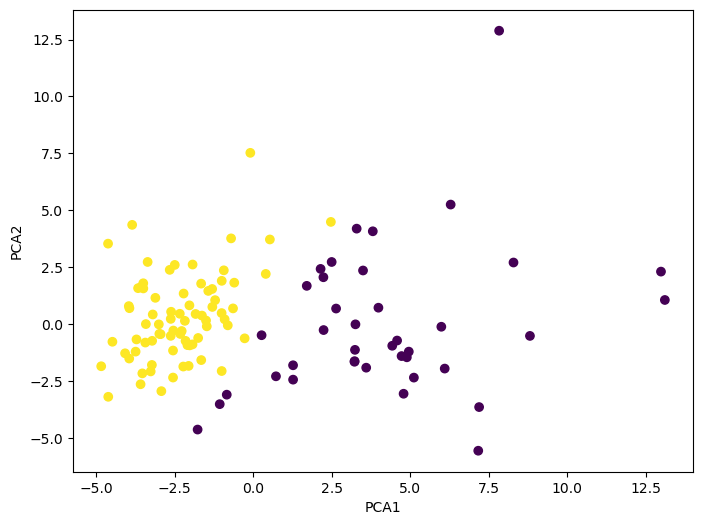

In [40]:
#Visualization
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(x_test_pca[:,0],x_test_pca[:,1],c=y_pred_pca) #c controls color of each point, based on its predicted class(predictions like 0 ,1 so keep 0=malignant n 1=benign colour)
#also [:,0]-means all rows of 0th index ie x(grabs pCA1 col), [:,1]--all rows of 1st index ie y(grabs pca2 col)
plt.xlabel('PCA1')
plt.ylabel('PCA2')

In [18]:
pca=PCA()
pca.fit(x_train_scaled)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [19]:
#This cell doesn't build a new PCA — it just summarizes whatever pca object is currently in memory into a running total. The number of values you get back always depends on how many components that specific pca object was configured with at the time you last ran its creation cell — not on the order cells appear in the notebook.
import numpy as np
#np.cumsum--cumulative sums up each component ie pc1, pc1+pc2, pc1_pc2_pc3,.... and gives running total so far
cumulative_variance=np.cumsum(pca.explained_variance_ratio_) #pulls out the list of "percentage of variance each component captures," from the pca object currently sitting in memory
print(cumulative_variance)
print(cumulative_variance.shape) #cumulative var of each component

[0.45752299 0.63908296 0.73235699 0.79471755 0.84734343 0.8871761
 0.91109883 0.9273759  0.94207974 0.95428845 0.96386295 0.97215183
 0.97904161 0.98412905 0.98719686 0.98992505 0.99177528 0.99347225
 0.99493993 0.99591828 0.99684201 0.99769724 0.99848802 0.99909904
 0.9994806  0.9997051  0.99992523 0.99997711 0.99999608 1.        ]
(30,)


[4.57522991e-01 1.81559971e-01 9.32740265e-02 6.23605605e-02
 5.26258815e-02 3.98326667e-02 2.39227372e-02 1.62770644e-02
 1.47038406e-02 1.22087104e-02 9.57449632e-03 8.28888788e-03
 6.88977613e-03 5.08744025e-03 3.06780538e-03 2.72819329e-03
 1.85022910e-03 1.69697356e-03 1.46767874e-03 9.78348283e-04
 9.23735823e-04 8.55229429e-04 7.90776360e-04 6.11018037e-04
 3.81561944e-04 2.24497231e-04 2.20128923e-04 5.18817895e-05
 1.89747122e-05 3.91712083e-06]


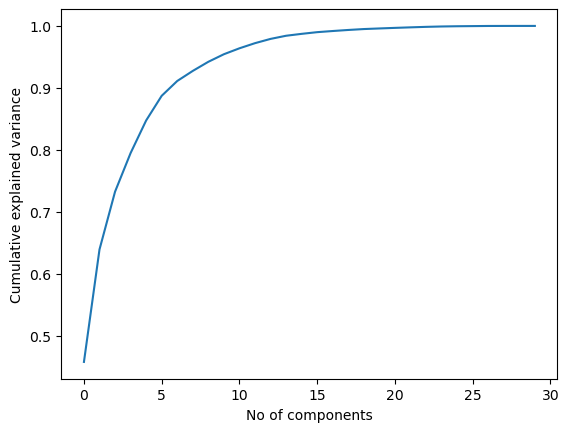

In [20]:
#How many components should we keep?
#Rule of thumb--keep enough components to explain 95% or more of total variance.
#explained_variance_ratio_ tells what percentage of original info each component preserves, we add them up until we hit our target(usually 90-95%)
#means here the original data will be actual dataset wothout applying pca and 
#explained_variance_ratio_-- means when pca creates new components(PCA1, PCA2...) each one captures a portion of that original 100% total variance
#explained_variance_ratio_--tells us what % of that original dataset total variance each new component manages to capture
#mhnje jr 50 col cha actual dataset ahe tr explaine_ration he sangta ki each new componnet banlay tr pratek component ni kito % madhe tya components ni total varianve capture karaycha try kela
import numpy as np
pca=PCA().fit(x_train_scaled)
print(pca.explained_variance_ratio_) #explained_variance_ratio_ —  (for finding "how many components for 95% variance"). That number IS derived directly from eigenvalues
explained=np.cumsum(pca.explained_variance_ratio_)

plt.plot(explained)
plt.xlabel('No of components')
plt.ylabel('Cumulative explained variance')
plt.show()

#Simple rule: e-01 means move the decimal point 1 place left, e-02 means move it 2 places left, and so on. The further right after the e-, the smaller the number.
#pca.explained_variance_ratio_
# [0.982, 0.0162, 0.00156, 0.000121, ...]
#means PCA alone captures 98.2% of total variance, PC2 adds only 1.62%, PC3 adds 0.156%, after that all is negligible
#By the time you add just PC1 + PC2, you're already at 99.8% — meaning 2 components alone almost perfectly preserve your entire original dataset's information.



#Hence this shows that it took 9 components to get the model a stable numbers thats why he plot shows you the full climb from 1 component up to all of them, so you can visually spot where it crosses 90-95%.


In [45]:
#Actually stores the full transformation, though nothing is reduced since no limit was set

pca=PCA()
x_train_pca=pca.fit_transform(x_train_scaled)
x_test_pca=pca.transform(x_test_scaled)
print('No of component selected:',pca.n_components_)

No of component selected: 30


In [ ]:
#Why Logistic Regression is in the picture 
#PCA's job is to compress features into smaller number, while keeping most of the useful info
#LR actually makes the prediction(maligant vs benign) using whatever features its given
#PCA never predicts anything on its own, its an unsup it has no concept of maligant or benign
#It just reshapes data, we still need an actual classifier(LR) to take that reshape data and produce a real prediction
#PCA is a preprocessing step and not a model itself
#PCA only transforms your features (X) — it's completely independent of which supervised algorithm you use afterward. You can pair it with Logistic Regression, Decision Tree, KNN, SVM, or anything else. 
#It tends to help distance-based algorithms (KNN, SVM) the most, and interpretable models like Decision Trees the least.

In [ ]:
#KNN and SVM → often benefit a lot, since they're distance-based and suffer from the "curse of dimensionality" (remember this from your KNN notes) — fewer, cleaner dimensions can genuinely improve both speed and accuracy
#Logistic Regression → commonly benefits too, especially when there are many correlated/redundant features
#Decision Tree → benefits less typically, since trees already handle many features reasonably well on their own, and PCA's compressed components are harder to interpret (you lose the nice "this feature > this value" splits that make trees so readable)

In [ ]:
#MY Prcatice example--using LOgisticRegression

In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

In [25]:
from sklearn import datasets

In [26]:
print(dir(datasets))

['__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__getattr__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_arff_parser', '_base', '_california_housing', '_covtype', '_kddcup99', '_lfw', '_olivetti_faces', '_openml', '_rcv1', '_samples_generator', '_species_distributions', '_svmlight_format_fast', '_svmlight_format_io', '_twenty_newsgroups', 'clear_data_home', 'data', 'descr', 'dump_svmlight_file', 'fetch_20newsgroups', 'fetch_20newsgroups_vectorized', 'fetch_california_housing', 'fetch_covtype', 'fetch_file', 'fetch_kddcup99', 'fetch_lfw_pairs', 'fetch_lfw_people', 'fetch_olivetti_faces', 'fetch_openml', 'fetch_rcv1', 'fetch_species_distributions', 'get_data_home', 'load_breast_cancer', 'load_diabetes', 'load_digits', 'load_files', 'load_iris', 'load_linnerud', 'load_sample_image', 'load_sample_images', 'load_svmlight_file', 'load_svmlight_files', 'load_wine', 'make_biclusters', 'make_blobs', 'make_checkerboard', 'make_circles', 'make_classificat

In [28]:
data=datasets.load_wine()
#print(data)

In [36]:
x=data.data
y=data.target
print(data.feature_names)
print(x[:,5])
#print(data.head())

#.head() only works on pandas DataFrames. sklearn's built-in datasets (load_wine(), load_breast_cancer(), load_iris(), etc.) return a Bunch object — to preview it nicely like a table, 
#you first need to wrap it with pd.DataFrame(data.data, columns=data.feature_names).

['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
[2.8  2.65 2.8  3.85 2.8  3.27 2.5  2.6  2.8  2.98 2.95 2.2  2.6  3.1
 3.3  2.85 2.8  2.95 3.3  2.7  3.   2.41 2.61 2.48 2.53 2.63 2.85 2.4
 2.95 2.65 3.   2.86 2.42 2.95 2.35 2.7  2.6  2.45 2.4  3.   3.15 2.45
 3.25 2.64 3.   2.85 3.25 3.1  2.75 2.88 2.72 2.45 3.88 3.   2.6  2.96
 3.2  3.   3.4  1.98 2.05 2.02 2.1  3.5  1.89 2.42 2.98 2.11 2.53 1.85
 1.1  2.95 1.88 3.3  3.38 1.61 1.95 1.72 1.9  2.83 2.42 2.2  2.   1.65
 2.2  2.2  1.78 1.92 1.95 2.2  1.6  1.45 1.38 2.45 3.02 2.5  1.6  2.55
 3.52 2.85 2.23 1.45 2.56 2.5  2.2  1.68 1.65 1.38 2.36 2.74 3.18 2.55
 1.75 2.48 2.56 2.46 1.98 2.   1.63 2.   2.9  3.18 2.2  2.62 2.86 2.6
 2.74 2.13 2.22 2.1  1.51 1.3  1.15 1.7  2.   1.62 1.38 1.79 1.62 2.32
 1.54 1.4  1.55 2.   1.38 1.5  0.98 1.7  1.93 1.41 1.4  1.48 2.2  1.8
 1.48 1.74 1.

In [37]:
print('Original shape:',x.shape)

Original shape: (178, 13)


In [39]:
#split data
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [40]:
#scale data
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [41]:
pca=PCA(n_components=2)

In [42]:
x_train_pca=pca.fit_transform(x_train_scaled)
x_test_pca=pca.transform(x_test_scaled)

In [44]:
print('After pca shape:',x_train_pca.shape)

After pca shape: (142, 2)


In [45]:
model=LogisticRegression()
model.fit(x_train_pca,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [47]:
y_pred_pca=model.predict(x_test_pca)
y_pred_pca

array([0, 0, 2, 0, 1, 0, 1, 2, 1, 2, 0, 2, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 2, 2, 2, 1, 1, 1, 0, 0, 1, 2, 0, 0, 0])

In [48]:
print('PCA accuracy:',accuracy_score(y_test,y_pred_pca))

PCA accuracy: 1.0


In [49]:
#prediction without pca
model=LogisticRegression()
model.fit(x_train,y_train)

F:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [50]:
y_pred=model.predict(x_test)
y_pred

array([0, 0, 2, 0, 1, 0, 1, 2, 1, 2, 1, 2, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 2, 2, 2, 1, 1, 1, 0, 0, 1, 2, 0, 0, 0])

In [52]:
print('Accurcay without applying pca:',accuracy_score(y_test,y_pred))

Accurcay without applying pca: 0.9722222222222222


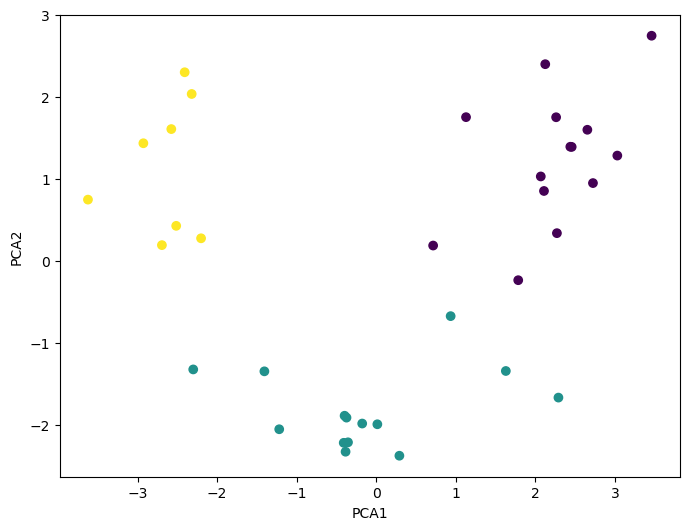

In [54]:
#Visualize
plt.figure(figsize=(8,6))
plt.scatter(x_test_pca[:,0],x_test_pca[:,1],c=y_pred_pca)
plt.xlabel('PCA1')
plt.ylabel('PCA2')
plt.show()

[0.35900066 0.18691934 0.11606557 0.07371716 0.0665386  0.04854582
 0.04195042 0.02683922 0.0234746  0.01889734 0.01715943 0.01262928
 0.00826257]


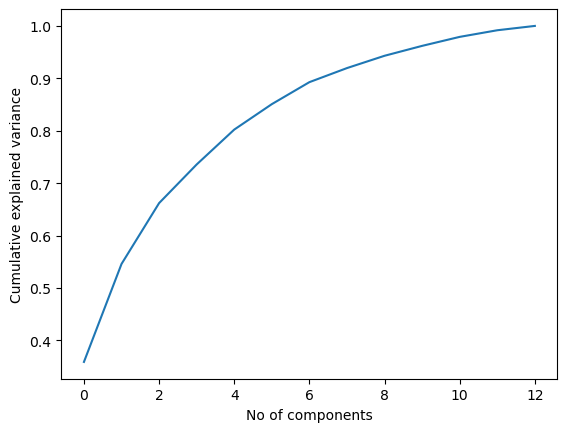

In [55]:
pca=PCA().fit(x_train_scaled)
print(pca.explained_variance_ratio_)
explained=np.cumsum(pca.explained_variance_ratio_)

plt.plot(explained)
plt.xlabel('No of components')
plt.ylabel('Cumulative explained variance')
plt.show()

In [56]:
#decide how many compoenets to keep using cumulative sum
cumulative_variance=np.cumsum(pca.explained_variance_ratio_) #pulls out the list of "percentage of variance each component captures," from the pca object currently sitting in memory
print(cumulative_variance)
print(cumulative_variance.shape) #cumulative var of each component

[0.35900066 0.54592    0.66198557 0.73570273 0.80224132 0.85078714
 0.89273756 0.91957678 0.94305138 0.96194872 0.97910815 0.99173743
 1.        ]
(13,)


In [58]:
#decide how many componenets to keep using code
n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Components needed:", n_components_95)

Components needed: 10


In [57]:
pca=PCA()
x_train_pca=pca.fit_transform(x_train_scaled)
x_test_pca=pca.transform(x_test_scaled)
print('No of component selected:',pca.n_components_)

No of component selected: 13


In [ ]:
#Example 2 -- using KNN

In [43]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.datasets import load_digits

In [44]:
data2=datasets.load_digits()

In [45]:
x=data2.data
y=data2.target
print(data2.feature_names)
print(x[:,5])

['pixel_0_0', 'pixel_0_1', 'pixel_0_2', 'pixel_0_3', 'pixel_0_4', 'pixel_0_5', 'pixel_0_6', 'pixel_0_7', 'pixel_1_0', 'pixel_1_1', 'pixel_1_2', 'pixel_1_3', 'pixel_1_4', 'pixel_1_5', 'pixel_1_6', 'pixel_1_7', 'pixel_2_0', 'pixel_2_1', 'pixel_2_2', 'pixel_2_3', 'pixel_2_4', 'pixel_2_5', 'pixel_2_6', 'pixel_2_7', 'pixel_3_0', 'pixel_3_1', 'pixel_3_2', 'pixel_3_3', 'pixel_3_4', 'pixel_3_5', 'pixel_3_6', 'pixel_3_7', 'pixel_4_0', 'pixel_4_1', 'pixel_4_2', 'pixel_4_3', 'pixel_4_4', 'pixel_4_5', 'pixel_4_6', 'pixel_4_7', 'pixel_5_0', 'pixel_5_1', 'pixel_5_2', 'pixel_5_3', 'pixel_5_4', 'pixel_5_5', 'pixel_5_6', 'pixel_5_7', 'pixel_6_0', 'pixel_6_1', 'pixel_6_2', 'pixel_6_3', 'pixel_6_4', 'pixel_6_5', 'pixel_6_6', 'pixel_6_7', 'pixel_7_0', 'pixel_7_1', 'pixel_7_2', 'pixel_7_3', 'pixel_7_4', 'pixel_7_5', 'pixel_7_6', 'pixel_7_7']
[ 1.  5. 12. ...  1.  0.  1.]


In [46]:
#check shape
print('original shape:',x.shape)

original shape: (1797, 64)


In [47]:
#split data
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [48]:
#scale data using StandardScaler
scale=StandardScaler()
x_train_scale=scale.fit_transform(x_train)
x_test_scale=scale.transform(x_test)

[0.12038006 0.09733098 0.08561821 0.06493777 0.04887914 0.04264048
 0.03949359 0.03349634 0.03023564 0.02931935 0.02772034 0.02544597
 0.02303063 0.02284083 0.02121741 0.01896257 0.01747417 0.01604341
 0.0158501  0.01508824 0.01339746 0.01273262 0.01138241 0.01043294
 0.00985377 0.00937385 0.00853172 0.00836261 0.00797069 0.00757462
 0.007004   0.00690267 0.00642917 0.00612906 0.00574282 0.00537687
 0.00502651 0.00476078 0.0045189  0.00429742 0.00410624 0.00388944
 0.00358723 0.00336731 0.00318305 0.00307454 0.00281831 0.00270809
 0.00253325 0.00227953 0.00215433 0.00191891 0.00187481 0.00179313
 0.00160614 0.00153293 0.00143078 0.00128793 0.00123173 0.00103578
 0.00078047 0.         0.         0.        ]


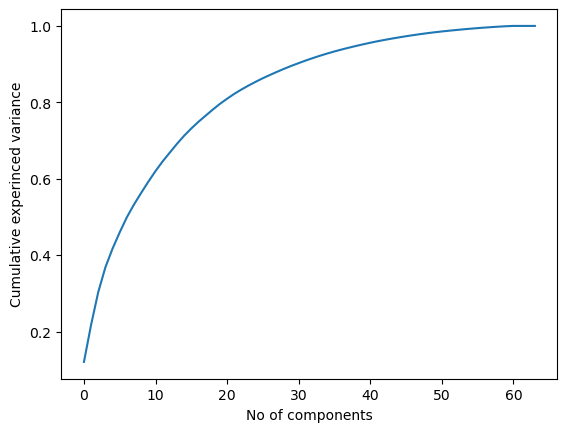

In [49]:
pca=PCA().fit(x_train_scale)
print(pca.explained_variance_ratio_)
explained=np.cumsum(pca.explained_variance_ratio_)

plt.plot(explained)
plt.xlabel('No of components')
plt.ylabel('Cumulative experinced variance')
plt.show()

In [50]:
#how many compoennets need to keep
cumulative_variance_KNN=np.cumsum(pca.explained_variance_ratio_)
print(cumulative_variance_KNN)
print(cumulative_variance_KNN.shape)

[0.12038006 0.21771104 0.30332925 0.36826702 0.41714616 0.45978663
 0.49928022 0.53277655 0.56301219 0.59233154 0.62005188 0.64549785
 0.66852848 0.6913693  0.71258671 0.73154928 0.74902345 0.76506686
 0.78091696 0.7960052  0.80940266 0.82213528 0.8335177  0.84395064
 0.85380441 0.86317825 0.87170997 0.88007258 0.88804326 0.89561788
 0.90262188 0.90952455 0.91595372 0.92208277 0.92782559 0.93320246
 0.93822897 0.94298975 0.94750865 0.95180607 0.95591232 0.95980176
 0.96338899 0.9667563  0.96993935 0.97301389 0.97583219 0.97854028
 0.98107353 0.98335306 0.98550739 0.9874263  0.98930111 0.99109424
 0.99270038 0.99423331 0.99566409 0.99695202 0.99818375 0.99921953
 1.         1.         1.         1.        ]
(64,)


In [51]:
n_components_95_KNN=np.argmax(cumulative_variance_KNN>=0.95)+1
print('Compenents needed:',n_components_95_KNN)

Compenents needed: 40


In [52]:
#apply pca
pca=PCA(n_components=40)

In [53]:
x_train_pca_KNN=pca.fit_transform(x_train_scale)
x_test_pca_KNN=pca.transform(x_test_scale)

In [54]:
print('Shape after applying pca:',x_train_pca_KNN.shape)

Shape after applying pca: (1437, 40)


In [55]:
#apply model
model_KNN=KNeighborsClassifier(n_neighbors=5)
model_KNN.fit(x_train_pca_KNN,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [56]:
y_pred_pca_KNN=model_KNN.predict(x_test_pca_KNN)
y_pred_pca_KNN

array([6, 9, 3, 7, 2, 1, 5, 2, 5, 2, 1, 9, 4, 0, 4, 2, 3, 7, 8, 8, 4, 3,
       9, 7, 5, 6, 3, 5, 6, 3, 4, 9, 1, 4, 4, 6, 9, 4, 7, 6, 6, 9, 1, 3,
       6, 1, 3, 0, 6, 5, 5, 1, 3, 5, 6, 0, 9, 0, 0, 1, 0, 4, 5, 2, 4, 5,
       7, 0, 7, 5, 9, 9, 5, 4, 7, 0, 4, 5, 5, 9, 9, 0, 2, 3, 8, 0, 6, 4,
       4, 9, 1, 2, 8, 3, 5, 2, 9, 0, 4, 4, 4, 3, 5, 3, 1, 3, 5, 9, 4, 2,
       7, 7, 4, 4, 1, 9, 2, 7, 8, 7, 2, 6, 9, 4, 0, 7, 2, 7, 5, 8, 5, 5,
       7, 9, 0, 6, 6, 4, 2, 8, 0, 9, 4, 6, 8, 9, 6, 9, 0, 3, 5, 6, 6, 0,
       6, 4, 2, 9, 3, 9, 7, 2, 9, 0, 4, 5, 3, 6, 5, 9, 9, 8, 4, 2, 1, 3,
       7, 7, 2, 2, 3, 9, 8, 0, 3, 2, 2, 5, 6, 9, 9, 4, 1, 5, 4, 2, 3, 6,
       4, 8, 5, 9, 5, 7, 8, 9, 4, 8, 1, 5, 4, 4, 9, 6, 1, 8, 6, 0, 4, 5,
       2, 7, 4, 6, 4, 5, 6, 0, 3, 2, 3, 6, 7, 1, 5, 1, 4, 7, 6, 8, 1, 5,
       5, 1, 6, 2, 8, 8, 9, 5, 7, 6, 2, 2, 2, 3, 4, 8, 8, 3, 6, 0, 9, 7,
       7, 0, 1, 0, 4, 5, 1, 5, 3, 6, 0, 4, 1, 0, 0, 3, 6, 5, 9, 7, 3, 5,
       5, 9, 9, 8, 5, 3, 3, 2, 0, 5, 8, 3, 4, 0, 2,

In [65]:
print('Accurcay KNN with pca:',accuracy_score(y_test,y_pred_pca_KNN))

Accurcay KNN with pca: 0.975


In [58]:
print('Confusion matrix:\n',confusion_matrix(y_test,y_pred_pca_KNN))

Confusion matrix:
 [[33  0  0  0  0  0  0  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  0 33  0  0  0  0  0  0  0]
 [ 0  0  1 33  0  0  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  0  0  0 45  1  0  0  1]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  0  1  0 32  0  1]
 [ 0  1  0  0  0  0  0  0 29  0]
 [ 0  0  0  1  0  1  0  0  1 37]]


In [62]:
#without apply pca
model=KNeighborsClassifier(n_neighbors=5)
model.fit(x_train_scale,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [63]:
y_pred_KNN=model.predict(x_test)
y_pred_KNN

array([6, 9, 3, 7, 2, 1, 5, 2, 5, 2, 1, 1, 1, 0, 4, 2, 3, 7, 8, 8, 4, 3,
       9, 7, 1, 6, 3, 5, 6, 3, 4, 9, 1, 4, 4, 6, 9, 4, 7, 6, 6, 9, 1, 3,
       6, 1, 3, 0, 6, 5, 1, 1, 9, 5, 6, 0, 9, 0, 0, 1, 0, 4, 5, 2, 4, 5,
       1, 0, 7, 6, 9, 5, 5, 1, 7, 0, 4, 1, 9, 9, 9, 0, 2, 3, 8, 0, 6, 4,
       4, 9, 1, 2, 1, 3, 5, 2, 9, 0, 4, 4, 1, 3, 5, 3, 1, 1, 5, 1, 1, 2,
       7, 7, 4, 4, 1, 9, 1, 7, 8, 7, 2, 6, 9, 4, 0, 7, 2, 7, 5, 1, 7, 5,
       7, 8, 0, 6, 6, 4, 2, 1, 0, 9, 4, 6, 8, 8, 6, 9, 0, 6, 5, 6, 6, 0,
       6, 4, 3, 9, 3, 1, 7, 2, 9, 0, 4, 5, 8, 6, 5, 8, 8, 1, 4, 2, 1, 3,
       7, 1, 2, 2, 3, 9, 8, 0, 3, 1, 2, 5, 6, 9, 9, 4, 1, 5, 4, 2, 3, 6,
       4, 1, 5, 9, 5, 7, 1, 9, 4, 8, 1, 5, 0, 4, 9, 6, 1, 8, 6, 0, 4, 5,
       2, 7, 1, 6, 4, 5, 6, 0, 3, 2, 3, 6, 1, 1, 9, 1, 4, 1, 6, 8, 1, 5,
       5, 1, 0, 2, 1, 1, 1, 1, 7, 6, 2, 2, 2, 3, 4, 8, 1, 8, 6, 0, 8, 7,
       1, 0, 1, 0, 4, 3, 1, 5, 3, 6, 0, 1, 1, 0, 0, 3, 6, 8, 9, 1, 3, 5,
       9, 9, 9, 1, 5, 3, 3, 1, 0, 1, 1, 3, 4, 0, 2,

In [66]:
print('Accuracy_score without pca KNN:',accuracy_score(y_test,y_pred_KNN))

Accuracy_score without pca KNN: 0.8138888888888889
